**2D Grid World Environment with DQN**

In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from collections import deque
import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
class GridWorldEnv(gym.Env):
    """5x5 GridWorld with walls, a trap, and a goal."""

    def __init__(self, max_steps=100):
        super().__init__()

        self.size = 5
        self.start = (0, 0)
        self.goal = (4, 4)
        self.trap = (1, 3)
        self.max_steps = max_steps

        self.walls = {
            (1, 1),
            (3, 0),
            (3, 2),
        }

        # 0 = Up, 1 = Down, 2 = Left, 3 = Right
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Discrete(25)

        self.position = self.start
        self.elapsed_steps = 0

    def _get_state(self):
        row, col = self.position
        return row * self.size + col

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.position = self.start
        self.elapsed_steps = 0

        return self._get_state(), {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")

        moves = {
            0: (-1, 0),
            1: (1, 0),
            2: (0, -1),
            3: (0, 1),
        }

        row, col = self.position
        dr, dc = moves[int(action)]
        next_position = (row + dr, col + dc)

        next_row, next_col = next_position

        inside_grid = (
            0 <= next_row < self.size
            and 0 <= next_col < self.size
        )

        if inside_grid and next_position not in self.walls:
            self.position = next_position

        self.elapsed_steps += 1

        reward = -1
        terminated = False

        if self.position == self.goal:
            reward = 10
            terminated = True
        elif self.position == self.trap:
            reward = -10
            terminated = True

        truncated = (
            self.elapsed_steps >= self.max_steps
            and not terminated
        )

        info = {"position": self.position}

        return (
            self._get_state(),
            reward,
            terminated,
            truncated,
            info,
        )

    def render(self):
        for row in range(self.size):
            cells = []

            for col in range(self.size):
                pos = (row, col)

                if pos == self.position:
                    symbol = "A"
                elif pos == self.goal:
                    symbol = "G"
                elif pos == self.trap:
                    symbol = "T"
                elif pos in self.walls:
                    symbol = "X"
                else:
                    symbol = "."

                cells.append(symbol)

            print(" ".join(cells))

        print()


Episode  100 | Reward:  -24.55 | Success:  39.0% | Epsilon: 0.606
Episode  200 | Reward:   -7.45 | Success:  74.0% | Epsilon: 0.367
Episode  300 | Reward:   -2.13 | Success:  84.0% | Epsilon: 0.222
Episode  400 | Reward:    0.53 | Success:  91.0% | Epsilon: 0.135
Episode  500 | Reward:    1.40 | Success:  96.0% | Epsilon: 0.082
Episode  600 | Reward:    2.16 | Success:  99.0% | Epsilon: 0.049
Episode  700 | Reward:    2.54 | Success:  99.0% | Epsilon: 0.030
Episode  800 | Reward:    2.85 | Success: 100.0% | Epsilon: 0.020
Episode  900 | Reward:    2.65 | Success:  99.0% | Epsilon: 0.020
Episode 1000 | Reward:    2.65 | Success:  99.0% | Epsilon: 0.020
Episode 1100 | Reward:    2.88 | Success: 100.0% | Epsilon: 0.020
Episode 1200 | Reward:    2.89 | Success: 100.0% | Epsilon: 0.020
Episode 1300 | Reward:    2.87 | Success: 100.0% | Epsilon: 0.020
Episode 1400 | Reward:    2.70 | Success:  99.0% | Epsilon: 0.020
Episode 1500 | Reward:    2.70 | Success:  99.0% | Epsilon: 0.020
Episode 16

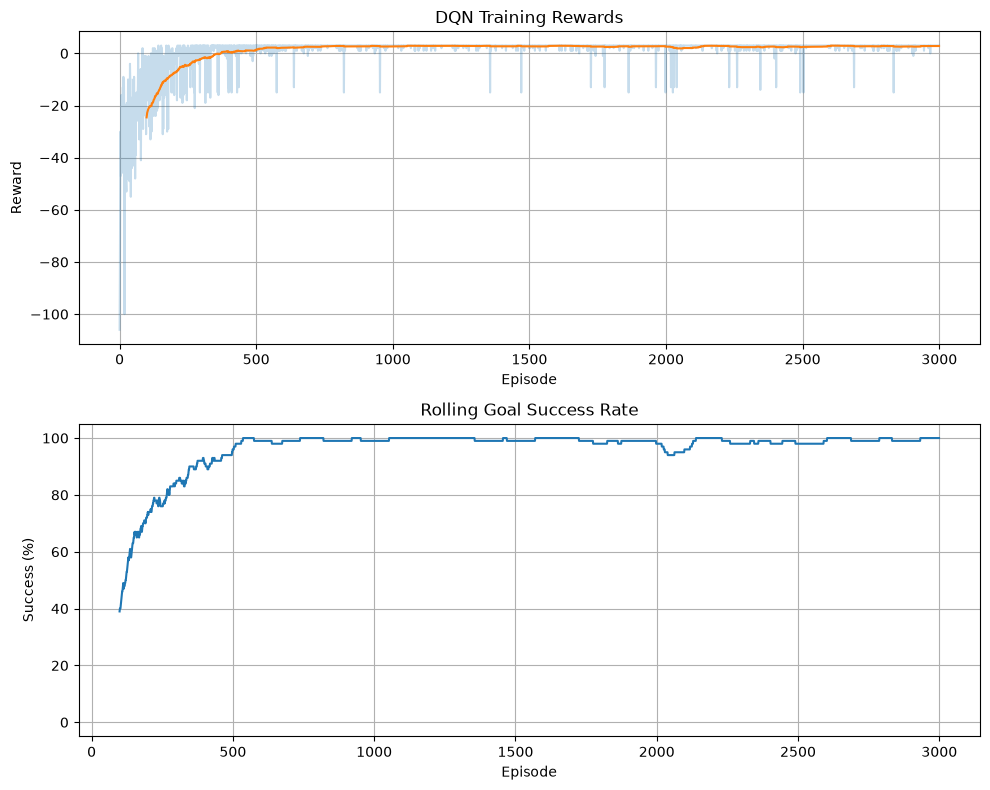

In [3]:
# DQN Training Loop

EPISODES = 3000
MAX_STEPS = 100

GAMMA = 0.95
LEARNING_RATE = 0.001

EPSILON_START = 1.0
EPSILON_MIN = 0.02
EPSILON_DECAY = 0.995

device = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE = torch.device(device) # mine work in cuda(

BATCH_SIZE = 64
BUFFER_SIZE = 20_000
WARMUP_STEPS = 500
TARGET_UPDATE_FREQ = 250

NUM_STATES = 25
NUM_ACTIONS = 4

# -------------------------
# Reproducibility
# -------------------------

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)


# -------------------------
# State encoding
# -------------------------

def encode_state(state):
    """Convert a discrete state into a 25-element one-hot vector."""

    vector = np.zeros(NUM_STATES, dtype=np.float32)
    vector[int(state)] = 1.0

    return vector

# -------------------------
# Q-Network
# -------------------------

class QNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(NUM_STATES, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, NUM_ACTIONS),
        )

    def forward(self, state):
        return self.network(state)
    

# -------------------------
# Replay Buffer
# -------------------------

class ReplayBuffer:
    def __init__(self, capacity):
        self.memory = deque(maxlen=capacity)

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        terminated,
    ):
        self.memory.append(
            (
                state,
                action,
                reward,
                next_state,
                terminated,
            )
        )

    def sample(self, batch_size):
        batch = random.sample(
            self.memory,
            batch_size,
        )

        states, actions, rewards, next_states, terminals = (
            zip(*batch)
        )

        return (
            np.asarray(states, dtype=np.float32),
            np.asarray(actions, dtype=np.int64),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(next_states, dtype=np.float32),
            np.asarray(terminals, dtype=np.float32),
        )

    def __len__(self):
        return len(self.memory)
    

# -------------------------
# Action selection
# -------------------------

def choose_action(state, epsilon, online_net, env):
    """Epsilon-greedy action selection."""

    if random.random() < epsilon:
        return env.action_space.sample()

    state_tensor = torch.as_tensor(
        encode_state(state),
        dtype=torch.float32,
        device=DEVICE,
    ).unsqueeze(0)

    with torch.no_grad():
        q_values = online_net(state_tensor)

    return int(q_values.argmax(dim=1).item())


# -------------------------
# DQN optimization
# -------------------------

def optimize_model(
    online_net,
    target_net,
    optimizer,
    replay_buffer,
):
    if len(replay_buffer) < BATCH_SIZE:
        return None

    (
        states,
        actions,
        rewards,
        next_states,
        terminated,
    ) = replay_buffer.sample(BATCH_SIZE)

    states = torch.as_tensor(
        states, device=DEVICE
    )
    actions = torch.as_tensor(
        actions, device=DEVICE
    ).unsqueeze(1)
    rewards = torch.as_tensor(
        rewards, device=DEVICE
    )
    next_states = torch.as_tensor(
        next_states, device=DEVICE
    )
    terminated = torch.as_tensor(
        terminated, device=DEVICE
    )

    # Q(s, a): predicted Q-value for the chosen action.
    current_q = online_net(states).gather(
        1, actions
    ).squeeze(1)

    # Target = reward + gamma * max Q_target(next_state)
    # No future value is added after true termination.
    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1).values

        target_q = rewards + GAMMA * (
            1.0 - terminated
        ) * next_q

    loss = nn.functional.smooth_l1_loss(
        current_q,
        target_q,
    )

    optimizer.zero_grad()
    loss.backward()

    # Helps avoid unstable, excessively large gradients.
    nn.utils.clip_grad_norm_(
        online_net.parameters(),
        max_norm=10.0,
    )

    optimizer.step()

    return loss.item()

# -------------------------
# Training
# -------------------------

def train():
    env = GridWorldEnv(max_steps=MAX_STEPS)

    online_net = QNetwork().to(DEVICE)
    target_net = QNetwork().to(DEVICE)

    target_net.load_state_dict(
        online_net.state_dict()
    )
    target_net.eval()

    optimizer = optim.Adam(
        online_net.parameters(),
        lr=LEARNING_RATE,
    )

    replay_buffer = ReplayBuffer(BUFFER_SIZE)

    epsilon = EPSILON_START
    total_steps = 0

    rewards_history = []
    success_history = []
    loss_history = []

    for episode in range(EPISODES):
        state, info = env.reset()
        episode_reward = 0
        success = 0

        for step in range(MAX_STEPS):
            # 1. Choose action.
            action = choose_action(
                state,
                epsilon,
                online_net,
                env,
            )

            # 2. Interact with environment.
            (
                next_state,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            # 3. Save the experience.
            replay_buffer.add(
                encode_state(state),
                action,
                reward,
                encode_state(next_state),
                terminated,
            )

            # 4. Train the online network.
            if total_steps >= WARMUP_STEPS:
                loss = optimize_model(
                    online_net,
                    target_net,
                    optimizer,
                    replay_buffer,
                )

                if loss is not None:
                    loss_history.append(loss)

            total_steps += 1

            # 5. Periodically update the target network.
            if total_steps % TARGET_UPDATE_FREQ == 0:
                target_net.load_state_dict(
                    online_net.state_dict()
                )

            state = next_state
            episode_reward += reward

            if terminated or truncated:
                if env.position == env.goal:
                    success = 1
                break

        rewards_history.append(episode_reward)
        success_history.append(success)

        # Decay exploration after each episode.
        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY,
        )

        if (episode + 1) % 100 == 0:
            avg_reward = np.mean(
                rewards_history[-100:]
            )
            avg_success = 100 * np.mean(
                success_history[-100:]
            )

            print(
                f"Episode {episode + 1:4d} | "
                f"Reward: {avg_reward:7.2f} | "
                f"Success: {avg_success:5.1f}% | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    history = {
        "rewards": rewards_history,
        "successes": success_history,
        "losses": loss_history,
    }

    return online_net, history


# -------------------------
# Evaluation
# -------------------------

def evaluate(online_net, episodes=100):
    env = GridWorldEnv(max_steps=MAX_STEPS)

    successes = 0
    traps = 0
    timeouts = 0
    rewards = []

    online_net.eval()

    for _ in range(episodes):
        state, info = env.reset()
        episode_reward = 0

        for step in range(MAX_STEPS):
            # Greedy action: no exploration.
            action = choose_action(
                state,
                0.0,
                online_net,
                env,
            )

            (
                state,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            episode_reward += reward

            if terminated or truncated:
                break

        if env.position == env.goal:
            successes += 1
        elif env.position == env.trap:
            traps += 1
        else:
            timeouts += 1

        rewards.append(episode_reward)

    print("\n========== DQN EVALUATION ==========")
    print(f"Episodes: {episodes}")
    print(f"Goals: {successes} ({successes / episodes:.1%})")
    print(f"Traps: {traps} ({traps / episodes:.1%})")
    print(f"Timeouts: {timeouts} ({timeouts / episodes:.1%})")
    print(f"Average reward: {np.mean(rewards):.2f}")

    env.close()
    online_net.train()


# -------------------------
# Plotting
# -------------------------

def plot_training(history):
    rewards = np.asarray(history["rewards"])
    successes = np.asarray(history["successes"])

    window = 100

    reward_avg = np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid",
    )

    success_avg = 100 * np.convolve(
        successes,
        np.ones(window) / window,
        mode="valid",
    )

    fig, axes = plt.subplots(
        2, 1, figsize=(10, 8)
    )

    axes[0].plot(rewards, alpha=0.25)
    axes[0].plot(
        np.arange(window - 1, len(rewards)),
        reward_avg,
    )
    axes[0].set_title("DQN Training Rewards")
    axes[0].set_xlabel("Episode")
    axes[0].set_ylabel("Reward")
    axes[0].grid(True)

    axes[1].plot(
        np.arange(window - 1, len(successes)),
        success_avg,
    )
    axes[1].set_title("Rolling Goal Success Rate")
    axes[1].set_xlabel("Episode")
    axes[1].set_ylabel("Success (%)")
    axes[1].set_ylim(-5, 105)
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig("dqn_training.png", dpi=150)
    plt.show()
    
# Main

online_net, history = train()

torch.save(
    online_net.state_dict(),
    "gridworld_dqn.pth",
)

print("\nSaved model to gridworld_dqn.pth")

evaluate(online_net)
plot_training(history)

In [4]:
# Inspect the saved model

def inspect_model():

    env = GridWorldEnv()
    model = QNetwork().to(DEVICE)

    model.load_state_dict(
        torch.load(
            "gridworld_dqn.pth",
            map_location=DEVICE,
            weights_only=True,
        )
    )

    model.eval()

    actions = ["Up", "Down", "Left", "Right"]

    for row in range(env.size):
        for col in range(env.size):

            pos = (row, col)

            if pos in env.walls:
                print(pos, "WALL")
                continue

            if pos == env.goal:
                print(pos, "GOAL")
                continue

            if pos == env.trap:
                print(pos, "TRAP")
                continue

            state = row * env.size + col

            state_tensor = torch.tensor(
                encode_state(state),
                dtype=torch.float32,
                device=DEVICE,
            ).unsqueeze(0)

            with torch.no_grad():
                q_values = model(state_tensor)[0]

            best_action = int(q_values.argmax())

            print(
                f"{pos} | "
                f"Best action: {actions[best_action]} | "
                f"Q-values: {q_values.cpu().numpy().round(2)}"
            )

    env.close()


inspect_model() # start inspecting the model


(0, 0) | Best action: Right | Q-values: [-0.04  0.95 -0.07  0.96]
(0, 1) | Best action: Right | Q-values: [ 0.96  1.   -0.06  2.08]
(0, 2) | Best action: Down | Q-values: [2.13 3.25 1.06 3.24]
(0, 3) | Best action: Right | Q-values: [  3.23 -10.     1.78   4.44]
(0, 4) | Best action: Down | Q-values: [4.45 5.73 3.24 4.46]
(1, 0) | Best action: Down | Q-values: [0.   2.07 1.06 0.99]
(1, 1) WALL
(1, 2) | Best action: Down | Q-values: [ 2.03  4.45  3.39 -9.27]
(1, 3) TRAP
(1, 4) | Best action: Down | Q-values: [  4.46   7.07 -10.48   5.11]
(2, 0) | Best action: Right | Q-values: [0.92 2.09 2.08 3.25]
(2, 1) | Best action: Right | Q-values: [3.2  4.44 2.1  4.47]
(2, 2) | Best action: Right | Q-values: [3.28 4.48 3.22 5.75]
(2, 3) | Best action: Right | Q-values: [-9.51  7.07  4.47  7.13]
(2, 4) | Best action: Down | Q-values: [5.71 8.49 5.76 7.11]
(3, 0) WALL
(3, 1) | Best action: Down | Q-values: [3.28 5.73 4.42 4.51]
(3, 2) WALL
(3, 3) | Best action: Right | Q-values: [5.74 8.5  7.09 8.5